# Filtros lineares e não-lineares
Média, Mediana, Moda e Máxima, sem OpenCV e com convolução manual.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, img_as_ubyte

In [3]:
def convolucao(img, kernel):
    kh, kw = kernel.shape
    ph, pw = kh // 2, kw // 2
    h, w = img.shape
    padded = np.pad(img.astype(np.float64), ((ph, ph), (pw, pw)), mode="constant")
    kernel = kernel[::-1, ::-1]
    saida = np.zeros((h, w), dtype=np.float64)
    for i in range(h):
        for j in range(w):
            saida[i, j] = np.sum(padded[i:i + kh, j:j + kw] * kernel)
    return saida


def aplicar_janela(img, tamanho, func):
    p = tamanho // 2
    h, w = img.shape
    padded = np.pad(img, p, mode="edge")
    saida = np.zeros_like(img)
    for i in range(h):
        for j in range(w):
            saida[i, j] = func(padded[i:i + tamanho, j:j + tamanho])
    return saida

In [4]:
def filtro_media(img, tamanho=3):
    kernel = np.ones((tamanho, tamanho)) / (tamanho * tamanho)
    return np.clip(convolucao(img, kernel), 0, 255).astype(np.uint8)


def filtro_mediana(img, tamanho=3):
    return aplicar_janela(img, tamanho, lambda v: np.sort(v, axis=None)[v.size // 2])


def filtro_moda(img, tamanho=3):
    def moda(v):
        valores, contagens = np.unique(v, return_counts=True)
        return valores[np.argmax(contagens)]
    return aplicar_janela(img, tamanho, moda)


def filtro_maximo(img, tamanho=3):
    return aplicar_janela(img, tamanho, lambda v: v.max())

In [5]:
img = io.imread("Viscous_Gloat.png")
if img.ndim == 3:
    img = color.rgb2gray(img[..., :3])
img = img_as_ubyte(img)

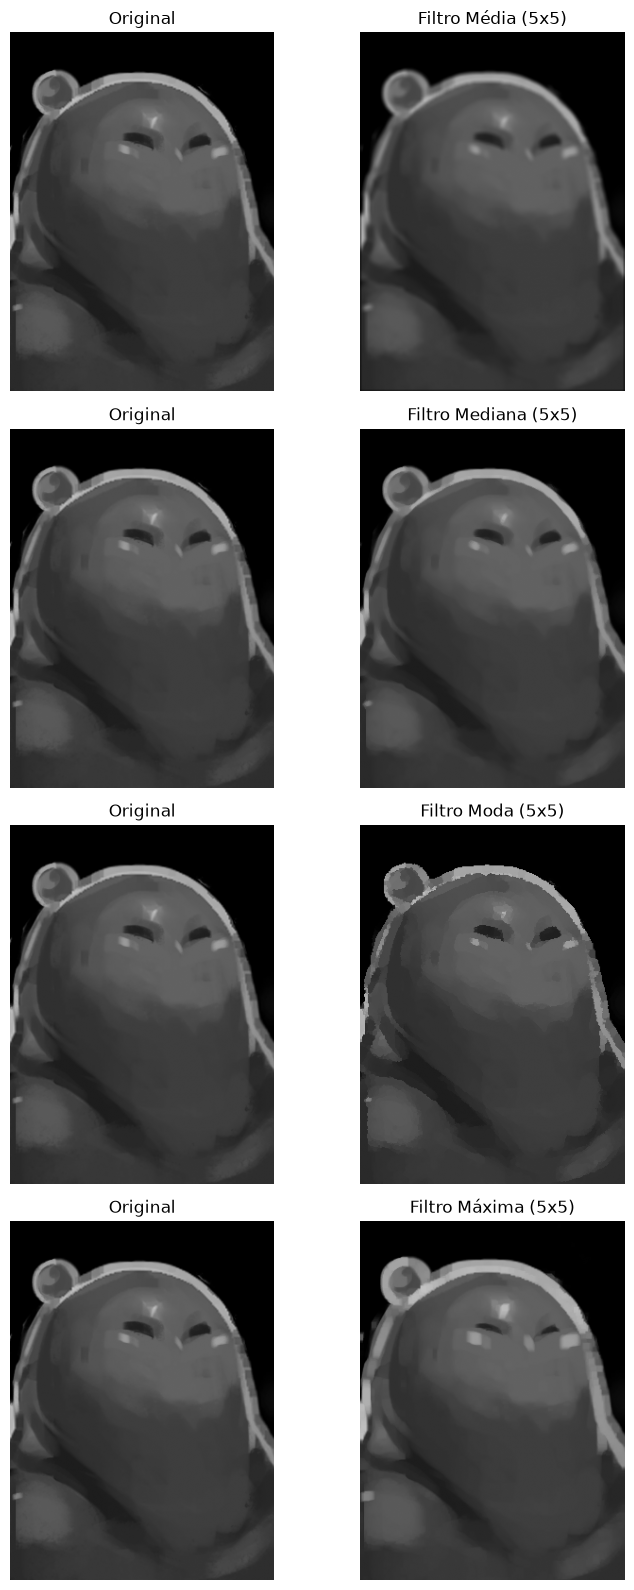

In [6]:
resultados = [
    ("Média", filtro_media(img, 5)),
    ("Mediana", filtro_mediana(img, 5)),
    ("Moda", filtro_moda(img, 5)),
    ("Máxima", filtro_maximo(img, 5)),
]

fig, eixos = plt.subplots(4, 2, figsize=(8, 16))
for linha, (nome, filtrada) in zip(eixos, resultados):
    linha[0].imshow(img, cmap="gray", vmin=0, vmax=255)
    linha[0].set_title("Original")
    linha[1].imshow(filtrada, cmap="gray", vmin=0, vmax=255)
    linha[1].set_title(f"Filtro {nome} (5x5)")
    for ax in linha:
        ax.axis("off")
plt.tight_layout()
plt.show()